Tổng số tham số: 99,476 (Giới hạn: < 100,000)
🚀 BẮT ĐẦU HUẤN LUYỆN...


Epoch 01 | Train Loss: 1.5541 | Train Acc: 46.28% | Val Loss: 1.1476 | Val Acc: 61.95%


Epoch 02 | Train Loss: 1.1136 | Train Acc: 64.59% | Val Loss: 0.9390 | Val Acc: 73.40%


Epoch 03 | Train Loss: 0.9577 | Train Acc: 72.26% | Val Loss: 0.8151 | Val Acc: 77.28%


Epoch 04 | Train Loss: 0.8740 | Train Acc: 75.42% | Val Loss: 0.7494 | Val Acc: 79.88%


Epoch 05 | Train Loss: 0.8110 | Train Acc: 78.39% | Val Loss: 0.7158 | Val Acc: 81.21%


... (66 outputs left out)

Epoch 72 | Train Loss: 0.5080 | Train Acc: 90.86% | Val Loss: 0.5200 | Val Acc: 90.38%


Epoch 73 | Train Loss: 0.5099 | Train Acc: 90.84% | Val Loss: 0.5189 | Val Acc: 90.56%


Epoch 74 | Train Loss: 0.5106 | Train Acc: 90.88% | Val Loss: 0.5172 | Val Acc: 90.56%


Epoch 75 | Train Loss: 0.5063 | Train Acc: 91.15% | Val Loss: 0.5185 | Val Acc: 90.49%

📈 ĐANG VẼ BIỂU ĐỒ QUÁ TRÌNH HUẤN LUYỆN...


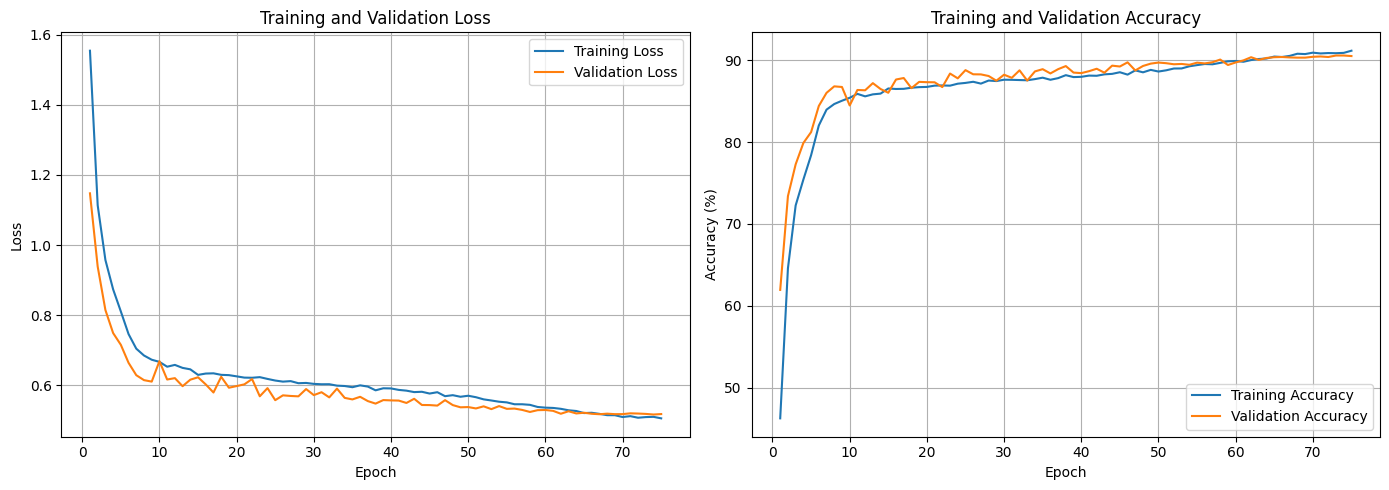


🎉 HOÀN TẤT HUẤN LUYỆN! Độ chính xác Val Acc cao nhất: 90.56%
Đang đánh giá lại trên tập Training để xuất Confusion Matrix...


Evaluating on Train Set: 100%|██████████| 2160/2160 [00:11<00:00, 181.31it/s]



--- CLASSIFICATION REPORT (TRAINING SET) ---
              precision    recall  f1-score   support

      16-QAM     0.7973    0.7729    0.7849      5760
        B-FM     0.9956    0.9858    0.9907      5760
        BPSK     0.8604    0.7790    0.8177      5760
      Barker     0.9990    0.9977    0.9983      5760
       CPFSK     0.9856    0.9736    0.9796      5760
      DSB-AM     0.8344    0.9797    0.9012      5760
        GFSK     0.9970    0.9882    0.9926      5760
         LFM     1.0000    1.0000    1.0000      5760
        PAM4     0.7707    0.8422    0.8049      5760
        QPSK     0.8360    0.7434    0.7870      5760
        Rect     0.9643    0.9839    0.9740      5760
      StepFM     0.9835    0.9648    0.9741      5760

    accuracy                         0.9176     69120
   macro avg     0.9187    0.9176    0.9171     69120
weighted avg     0.9187    0.9176    0.9171     69120



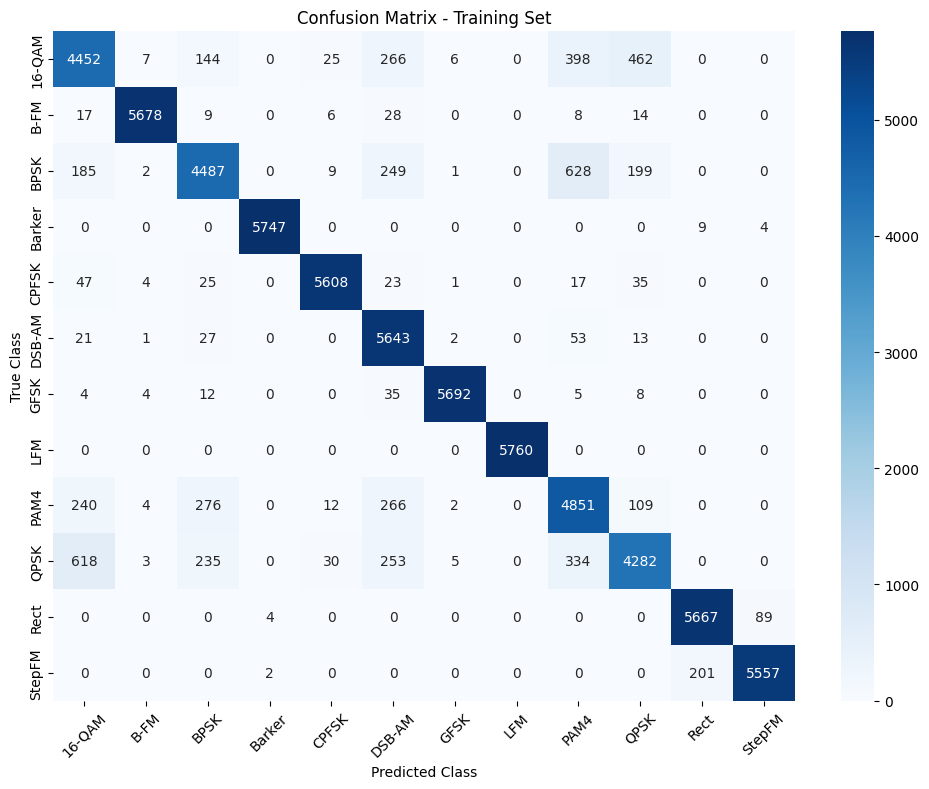


💾 ĐANG XUẤT FILE MÔ HÌNH...
Model saved 12_DeepLearningProject_TrainedModel.pt


In [1]:
import os
import random
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# =====================================================================
# 1. SETTINGS - CẤU HÌNH ĐÃ GỠ BỎ EMA LỖI
# =====================================================================
SEED = 42
BATCH_SIZE = 32
EPOCHS = 75            
LEARNING_RATE = 3e-3    
WEIGHT_DECAY = 0.02     
IMAGE_SIZE = 224       
VAL_RATIO = 0.1         
LABEL_SMOOTHING = 0.05  
USE_WEIGHTED_SAMPLER = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(SEED)

# =====================================================================
# 2. MODEL - KIẾN TRÚC ÉP CHUẨN ~98K THAM SỐ
# =====================================================================
class DeepCoordinateAttention(nn.Module):
    def __init__(self, channels, reduction=4):
        super().__init__()
        mid = max(8, channels // reduction)
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        self.conv1 = nn.Conv2d(channels, mid, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(mid)
        self.act = nn.SiLU()
        self.conv_h = nn.Conv2d(mid, channels, 1)
        self.conv_w = nn.Conv2d(mid, channels, 1)

    def forward(self, x):
        identity = x
        n, c, h, w = x.size()
        x_h = self.pool_h(x)
        x_w = self.pool_w(x).permute(0, 1, 3, 2)
        y = torch.cat([x_h, x_w], dim=2)
        y = self.act(self.bn1(self.conv1(y)))
        h_attn, w_attn = torch.split(y, [h, w], dim=2)
        out = identity * torch.sigmoid(self.conv_h(h_attn)) * torch.sigmoid(self.conv_w(w_attn.permute(0, 1, 3, 2)))
        return out

class OptimizedBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride, expand=2):
        super().__init__()
        mid = in_ch * expand
        self.identity = stride == 1 and in_ch == out_ch
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, mid, 1, bias=False),
            nn.BatchNorm2d(mid),
            nn.SiLU(),
            nn.Conv2d(mid, mid, 3, stride, 1, groups=mid, bias=False),
            nn.BatchNorm2d(mid),
            nn.SiLU(),
            DeepCoordinateAttention(mid),
            nn.Conv2d(mid, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
        )
        if not self.identity:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        return self.block(x) + (x if self.identity else self.shortcut(x))

class RadarClassifierV5(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, 2, 1, bias=False),
            nn.BatchNorm2d(16),
            nn.SiLU()
        )
        self.body = nn.Sequential(
            OptimizedBlock(16, 24, 2),
            OptimizedBlock(24, 32, 2), 
            OptimizedBlock(32, 48, 2), 
            OptimizedBlock(48, 64, 2), 
            OptimizedBlock(64, 68, 1), 
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(68, 256), 
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.head(self.body(self.stem(x)))

# =====================================================================
# 3. DATA
# =====================================================================
def build_dataloaders(data_dir):
    train_tf = transforms.Compose([
        transforms.RandomAffine(degrees=0, translate=(0.04, 0.04)), 
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
        transforms.RandomErasing(p=0.2, scale=(0.02, 0.1)), 
    ])
    eval_tf = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])

    ds = datasets.ImageFolder(data_dir)
    indices = np.arange(len(ds))
    train_idx, val_idx = train_test_split(indices, test_size=VAL_RATIO, stratify=ds.targets, random_state=SEED)

    train_ds = Subset(datasets.ImageFolder(data_dir, train_tf), train_idx)
    val_ds = Subset(datasets.ImageFolder(data_dir, eval_tf), val_idx)
    
    eval_train_ds = Subset(datasets.ImageFolder(data_dir, eval_tf), train_idx)
    eval_train_loader = DataLoader(eval_train_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=30)

    targets = np.array(ds.targets)[train_idx]
    count = Counter(targets)
    weights = torch.DoubleTensor([1.0/count[t] for t in targets])
    sampler = WeightedRandomSampler(weights, len(weights))

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=30, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=30)
    return ds.classes, train_loader, val_loader, eval_train_loader

# =====================================================================
# 4. TRAINING & ĐÁNH GIÁ
# =====================================================================
def main():
    DATA_DIR = "/kaggle/input/datasets/huynhthethien/radarcommunsignaldata2026train"
    classes, train_loader, val_loader, eval_train_loader = build_dataloaders(DATA_DIR)
    
    model = RadarClassifierV5(len(classes)).to(DEVICE)
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print("="*60)
    print(f"Tổng số tham số: {params:,} (Giới hạn: < 100,000)")
    print("="*60)
    if params >= 100000: 
        print("LỖI: Số lượng tham số vượt quá quy định!")
        return

    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LEARNING_RATE, 
                                             steps_per_epoch=len(train_loader), epochs=EPOCHS)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_acc = 0.0
    
    print("🚀 BẮT ĐẦU HUẤN LUYỆN...")
    for epoch in range(EPOCHS):
        model.train()
        train_loss, train_correct, train_total = 0.0, 0, 0
        
        for img, lbl in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}", leave=False):
            img, lbl = img.to(DEVICE), lbl.to(DEVICE)
            optimizer.zero_grad()
            out = model(img)
            loss = criterion(out, lbl)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            train_loss += loss.item() * img.size(0)
            train_correct += (out.argmax(1) == lbl).sum().item()
            train_total += lbl.size(0)

        epoch_train_loss = train_loss / train_total
        epoch_train_acc = 100 * train_correct / train_total

        # Đánh giá trực tiếp trên model (Không dùng EMA nữa)
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for img, lbl in val_loader:
                img, lbl = img.to(DEVICE), lbl.to(DEVICE)
                out = model(img)
                loss = criterion(out, lbl)
                
                val_loss += loss.item() * img.size(0)
                val_correct += (out.argmax(1) == lbl).sum().item()
                val_total += lbl.size(0)
        
        epoch_val_loss = val_loss / val_total
        epoch_val_acc = 100 * val_correct / val_total
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['train_acc'].append(epoch_train_acc)
        history['val_acc'].append(epoch_val_acc)
        
        print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")
        
        if epoch_val_acc > best_acc:
            best_acc = epoch_val_acc
            torch.save(model.state_dict(), "best.pth")

    # =================================================================
    # 5. VẼ ĐỒ THỊ LOSS VÀ ACCURACY
    # =================================================================
    print("\n📈 ĐANG VẼ BIỂU ĐỒ QUÁ TRÌNH HUẤN LUYỆN...")
    epochs_range = range(1, EPOCHS + 1)
    
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Training Loss')
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, history['train_acc'], label='Training Accuracy')
    plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.title('Training and Validation Accuracy')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.savefig('training_history.png')
    plt.show()

    # =================================================================
    # 6. ĐÁNH GIÁ TRÊN TẬP TRAIN (Để lập Báo Cáo)
    # =================================================================
    print(f"\n🎉 HOÀN TẤT HUẤN LUYỆN! Độ chính xác Val Acc cao nhất: {best_acc:.2f}%")
    print("Đang đánh giá lại trên tập Training để xuất Confusion Matrix...")
    
    model.load_state_dict(torch.load("best.pth", weights_only=True))
    model.eval()
    
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for img, lbl in tqdm(eval_train_loader, desc="Evaluating on Train Set"):
            img, lbl = img.to(DEVICE), lbl.to(DEVICE)
            out = model(img)
            all_preds.extend(out.argmax(1).cpu().numpy())
            all_labels.extend(lbl.cpu().numpy())
            
    print("\n--- CLASSIFICATION REPORT (TRAINING SET) ---")
    print(classification_report(all_labels, all_preds, target_names=classes, digits=4))
    
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
    plt.title('Confusion Matrix - Training Set')
    plt.ylabel('True Class')
    plt.xlabel('Predicted Class')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('confusion_matrix_train.png')
    plt.show()

    # =================================================================
    # 7. XUẤT FILE MÔ HÌNH (CẤM CHỈNH SỬA)
    # =================================================================
    print("\n💾 ĐANG XUẤT FILE MÔ HÌNH...")
    ############################################
    # DO NOT MODIFY THIS SECTION
    ############################################
    model.eval()
    example_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)
    traced_model = torch.jit.trace(model, example_input)
    GroupID = "12" 
    model_name = f"{GroupID}_DeepLearningProject_TrainedModel.pt"
    traced_model.save(model_name)
    print("Model saved", model_name)

if __name__ == "__main__":
    main()